# 06 — Isolation Forest : détection d'anomalies non supervisée (expérience complémentaire)

**Objectif.** Les notebooks 02–03 apprennent à partir d'étiquettes (`label`). Ici, on teste ce qu'un détecteur **sans étiquettes** peut faire : il apprend à quoi ressemble le trafic « habituel » et signale ce qui s'en écarte. C'est le cadre du comportement **inconnu / zero-day** : une attaque jamais vue n'a, par définition, aucun exemple étiqueté.

**Hypothèse centrale d'Isolation Forest.** L'algorithme isole chaque point par des coupures aléatoires ; les points **rares et éloignés** sont isolés en peu de coupures (chemin court = score d'anomalie élevé). Il suppose donc que les anomalies sont **minoritaires** et différentes de la masse des données.

**Pourquoi ce jeu de données viole cette hypothèse.** Dans TON_IoT, environ trois lignes sur quatre sont des **attaques** (`label = 1`) : c'est le trafic *normal* qui est minoritaire. Les attaques (scans, DoS, DDoS…) sont de plus très répétitives, donc denses. Le modèle risque de trouver « rare » le trafic normal, c'est-à-dire un score **inversé**. On le mesure plutôt que de le supposer.

**Protocole.**
- *Variante A (principale, strictement non supervisée)* : ajustement sur `X_train` sans aucune étiquette, aucun réglage d'après les étiquettes ; stabilité vérifiée sans étiquettes (corrélation de Spearman entre graines).
- *Variante B (semi-supervisée)* : ajustement sur les seules lignes « normal » du train (détection de nouveauté).
- Les étiquettes ne servent qu'à **évaluer** (jeu de test lu une seule fois, à la fin de chaque variante). Un seuil « oracle » (qui connaît la proportion d'attaques) est rapporté à part, comme plafond du classement des scores, non déployable.

In [1]:
import sys, time
sys.path.append("../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from scipy.stats import spearmanr
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
import ml_utils as U
U.set_style(); U.set_seeds()

cfg = U.load_config()
X_train, y_train = U.load_split("train")
X_test, y_test = U.load_split("test")   # lu une seule fois ; la validation n'est pas utilisée (aucun réglage)
num_cols, cat_cols = cfg["numeric_cols"], cfg["categorical_cols"]
N_JOBS, SEED = 4, U.RANDOM_STATE
IF_PARAMS = dict(n_estimators=300, contamination="auto", max_samples="auto")
print("tailles :", X_train.shape, X_test.shape)
print(f"part d'attaques — train : {y_train['label'].mean():.3f} | test : {y_test['label'].mean():.3f}  (le normal est la minorité)")


def make_if(seed=SEED):
    pre = U.make_preprocessor(num_cols, cat_cols, scale=False)   # arbres : pas de standardisation
    return Pipeline([("pre", pre), ("model", IsolationForest(**IF_PARAMS, random_state=seed, n_jobs=N_JOBS))])


def evaluate(pipe, X, y, name):
    """Scores d'anomalie (-score_samples), décision par défaut (predict == -1 -> attaque) et métriques."""
    score = -pipe.score_samples(X)
    pred = (pipe.predict(X) == -1).astype(int)
    m = U.binary_metrics(y, pred, scores=score)
    print(f"[{name}] " + " | ".join(f"{k}={m[k]:.4f}" for k in
          ["precision", "recall", "specificity", "f1", "f1_macro", "f1_weighted", "mcc", "roc_auc", "pr_auc"]))
    return score, pred, m


def oracle(score, y):
    """ORACLE (utilise les étiquettes) : on marque les q % scores les plus hauts, q = vraie part d'attaques."""
    q = float(np.mean(y)); thr = np.quantile(score, 1 - q)
    pred = (score >= thr).astype(int)
    return U.binary_metrics(y, pred, scores=score), q, float(thr)

tailles : (65007, 35) (21438, 35)
part d'attaques — train : 0.767 | test : 0.773  (le normal est la minorité)


## Variante A — non supervisée (aucune étiquette à l'apprentissage)

Le préprocesseur (imputation, log1p, one-hot ; pas de standardisation, inutile pour des arbres) et la forêt (300 arbres, `contamination="auto"`) sont ajustés sur `X_train` seul. Aucun hyperparamètre n'est ajusté d'après les étiquettes. La **stabilité** est contrôlée sans étiquettes : 5 graines, corrélation de rang (Spearman) des scores d'anomalie sur le test.

In [2]:
yt = y_test["label"].to_numpy()
t0 = time.perf_counter(); pipe_a = make_if().fit(X_train); fit_a = time.perf_counter() - t0
print(f"ajustement A : {fit_a:.1f} s sur {len(X_train)} lignes (sans étiquettes)")

# stabilité (sans étiquettes) : préprocesseur fixe, forêts de graines différentes
Z_train, Z_test = pipe_a["pre"].transform(X_train), pipe_a["pre"].transform(X_test)
seeds = [0, 1, 2, 3, 4]
sc = {s: -IsolationForest(**IF_PARAMS, random_state=s, n_jobs=N_JOBS).fit(Z_train).score_samples(Z_test) for s in seeds}
rho = pd.DataFrame([[spearmanr(sc[a], sc[b])[0] for b in seeds] for a in seeds], index=seeds, columns=seeds)
off = rho.values[np.triu_indices(5, 1)]
stability = {"seeds": seeds, "spearman_mean": float(off.mean()), "spearman_min": float(off.min())}
print(rho.round(4)); print("stabilité :", stability)

score_a, pred_a, m_a = evaluate(pipe_a, X_test, yt, "A défaut")
pt_a = U.measure_predict_time(pipe_a.predict, X_test)
print(f"part de lignes signalées : {pred_a.mean():.3f} (part réelle d'attaques : {yt.mean():.3f}) | prédiction : {pt_a:.1f} ms / 1000 lignes")
print(f"ROC-AUC du score = {m_a['roc_auc']:.4f} -> " + ("SCORE INVERSÉ (<0.5) : le normal est jugé plus anormal que les attaques" if m_a['roc_auc'] < 0.5 else "score dans le bon sens"))
m_or, q, thr = oracle(score_a, yt)
print(f"[A ORACLE, utilise les étiquettes] q={q:.3f} seuil={thr:.4f} | " + " | ".join(f"{k}={m_or[k]:.4f}" for k in ["precision", "recall", "specificity", "f1", "f1_macro", "mcc"]))
m_or_inv, _, _ = oracle(-score_a, yt)
print("[A ORACLE, score inversé (diagnostic)] " + " | ".join(f"{k}={m_or_inv[k]:.4f}" for k in ["precision", "recall", "specificity", "f1", "f1_macro", "mcc", "roc_auc"]))

ajustement A : 2.5 s sur 65007 lignes (sans étiquettes)


       0      1      2      3      4
0 1.0000 0.9942 0.9942 0.9941 0.9935
1 0.9942 1.0000 0.9935 0.9947 0.9927
2 0.9942 0.9935 1.0000 0.9922 0.9940
3 0.9941 0.9947 0.9922 1.0000 0.9932
4 0.9935 0.9927 0.9940 0.9932 1.0000
stabilité : {'seeds': [0, 1, 2, 3, 4], 'spearman_mean': 0.9936165502389844, 'spearman_min': 0.9921532410095233}


[A défaut] precision=0.4399 | recall=0.0959 | specificity=0.5843 | f1=0.1575 | f1_macro=0.2040 | f1_weighted=0.1786 | mcc=-0.3580 | roc_auc=0.1188 | pr_auc=0.5975


part de lignes signalées : 0.168 (part réelle d'attaques : 0.773) | prédiction : 26.3 ms / 1000 lignes
ROC-AUC du score = 0.1188 -> SCORE INVERSÉ (<0.5) : le normal est jugé plus anormal que les attaques
[A ORACLE, utilise les étiquettes] q=0.773 seuil=0.3859 | precision=0.7064 | recall=0.7064 | specificity=0.0000 | f1=0.7064 | f1_macro=0.3532 | mcc=-0.2936
[A ORACLE, score inversé (diagnostic)] precision=0.8680 | recall=0.8680 | specificity=0.5503 | f1=0.8680 | f1_macro=0.7092 | mcc=0.4184 | roc_auc=0.8812


## Variante B — semi-supervisée (utilise les étiquettes « normal » pour filtrer le train)

> **Attention : cette variante utilise les étiquettes** (uniquement pour retirer les attaques du train). Elle correspond à la détection de **nouveauté** : on modélise le trafic normal connu et on signale tout écart. Elle n'est plus « non supervisée » au sens strict, mais reste plausible en production si l'on dispose d'une période de trafic sain.

In [3]:
mask_n = (y_train["label"] == 0).to_numpy()
t0 = time.perf_counter(); pipe_b = make_if().fit(X_train.loc[mask_n]); fit_b = time.perf_counter() - t0
print(f"ajustement B : {fit_b:.1f} s sur {int(mask_n.sum())} lignes normales")
score_b, pred_b, m_b = evaluate(pipe_b, X_test, yt, "B défaut")
pt_b = U.measure_predict_time(pipe_b.predict, X_test)
print(f"part de lignes signalées : {pred_b.mean():.3f} | prédiction : {pt_b:.1f} ms / 1000 lignes")
print(f"ROC-AUC = {m_b['roc_auc']:.4f} -> " + ("score inversé" if m_b['roc_auc'] < 0.5 else "score dans le bon sens"))
m_or_b, _, thr_b = oracle(score_b, yt)
print(f"[B ORACLE, utilise les étiquettes] seuil={thr_b:.4f} | " + " | ".join(f"{k}={m_or_b[k]:.4f}" for k in ["precision", "recall", "specificity", "f1", "f1_macro", "mcc"]))

ajustement B : 1.2 s sur 15122 lignes normales


[B défaut] precision=0.9383 | recall=0.9557 | specificity=0.7859 | f1=0.9469 | f1_macro=0.8792 | f1_weighted=0.9162 | mcc=0.7592 | roc_auc=0.9156 | pr_auc=0.9362


part de lignes signalées : 0.787 | prédiction : 28.9 ms / 1000 lignes
ROC-AUC = 0.9156 -> score dans le bon sens
[B ORACLE, utilise les étiquettes] seuil=0.5120 | precision=0.9498 | recall=0.9498 | specificity=0.8290 | f1=0.9498 | f1_macro=0.8894 | mcc=0.7788


## Visualisations : distributions des scores, courbes ROC/PR, matrices de confusion

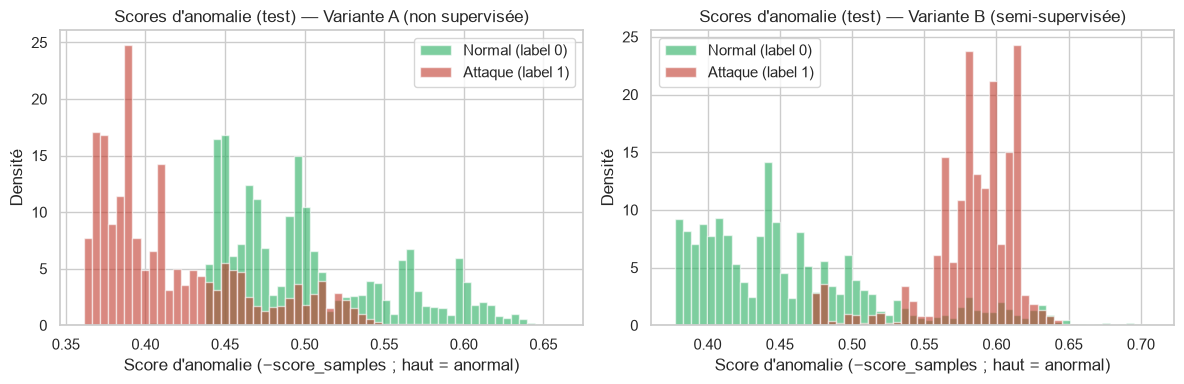

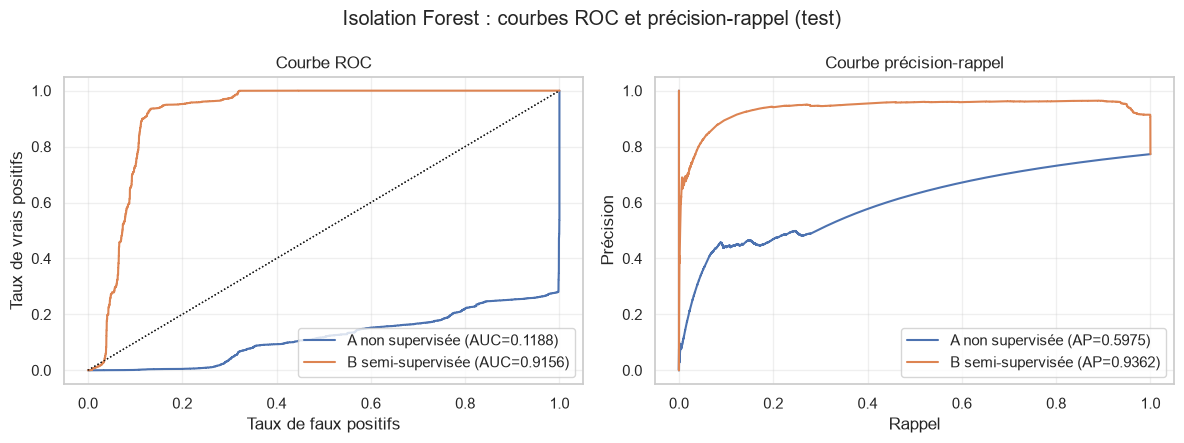

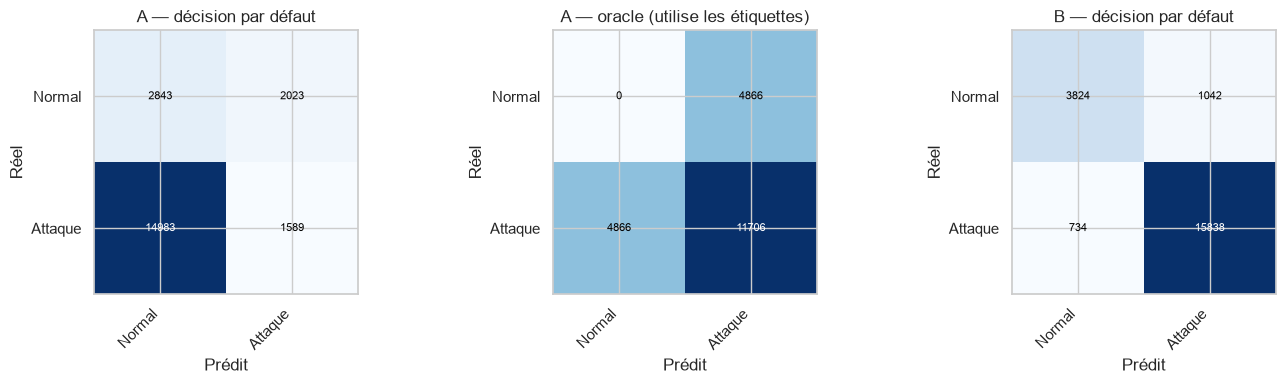

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, s, nm in [(axes[0], score_a, "Variante A (non supervisée)"), (axes[1], score_b, "Variante B (semi-supervisée)")]:
    bins = np.linspace(s.min(), s.max(), 60)
    ax.hist(s[yt == 0], bins=bins, alpha=.6, density=True, label="Normal (label 0)", color="#27ae60")
    ax.hist(s[yt == 1], bins=bins, alpha=.6, density=True, label="Attaque (label 1)", color="#c0392b")
    ax.set(title=f"Scores d'anomalie (test) — {nm}", xlabel="Score d'anomalie (−score_samples ; haut = anormal)", ylabel="Densité")
    ax.legend()
fig.tight_layout(); U.savefig(fig, "06_score_histograms"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
U.plot_roc_pr(yt, score_a, "A non supervisée", axes); U.plot_roc_pr(yt, score_b, "B semi-supervisée", axes)
fig.suptitle("Isolation Forest : courbes ROC et précision-rappel (test)"); fig.tight_layout()
U.savefig(fig, "06_roc_pr"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
U.plot_confusion([[m_a["tn"], m_a["fp"]], [m_a["fn"], m_a["tp"]]], ["Normal", "Attaque"], "A — décision par défaut", axes[0])
U.plot_confusion([[m_or["tn"], m_or["fp"]], [m_or["fn"], m_or["tp"]]], ["Normal", "Attaque"], "A — oracle (utilise les étiquettes)", axes[1])
U.plot_confusion([[m_b["tn"], m_b["fp"]], [m_b["fn"], m_b["tp"]]], ["Normal", "Attaque"], "B — décision par défaut", axes[2])
fig.tight_layout(); U.savefig(fig, "06_confusion"); plt.show()

## Taux de détection par type d'attaque et projection PCA

Le **taux de détection** d'un type est la part de ses lignes de test signalées comme anomalies (pour `normal`, c'est le taux de fausses alertes). La PCA (ajustée sur un échantillon de 5 000 lignes de test, uniquement pour visualiser) compare la vérité terrain à la décision du modèle.

            A non supervisée  B semi-supervisée  effectif test
normal                0.4157             0.2141           4866
ransomware            0.6559             1.0000            247
scanning              0.0868             0.9992           1187
backdoor              0.0124             1.0000            485
dos                   0.1478             0.9709           2882
mitm                  0.6919             0.9848            198
xss                   0.1559             0.9994           1745
ddos                  0.1261             0.7588           2657
injection             0.0273             1.0000           3956
password              0.0124             0.9988           3215


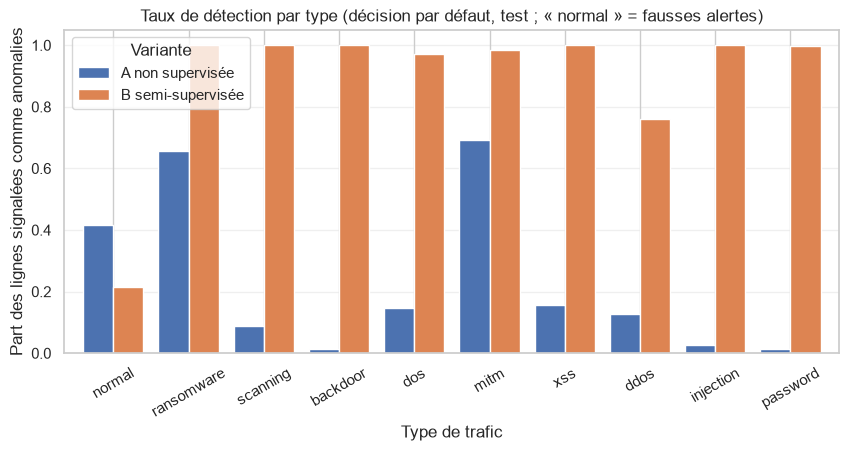

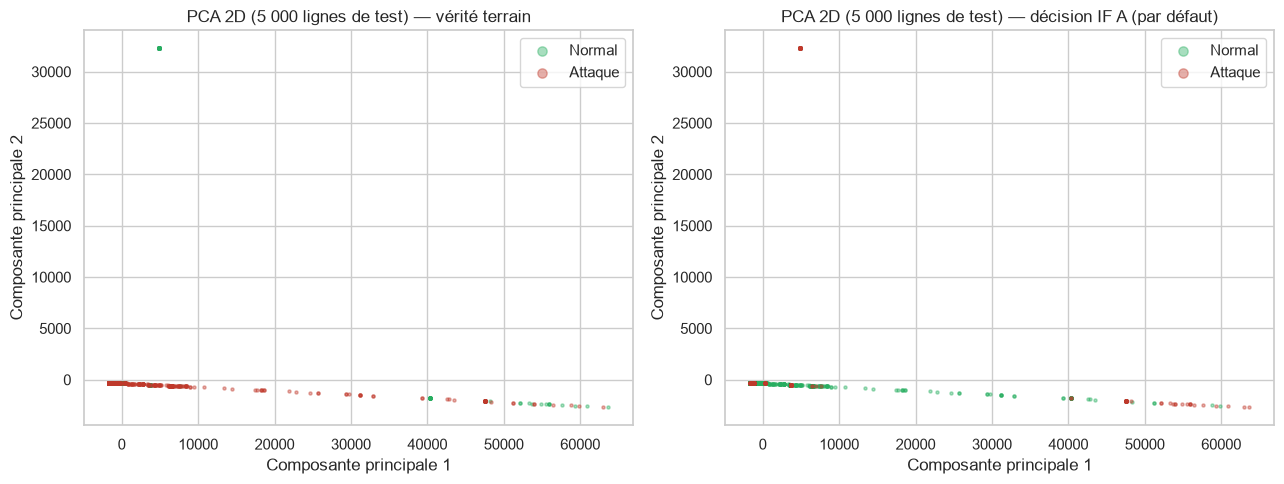

In [5]:
types = y_test["type"].to_numpy()
order = [t for t in cfg["type_order"] if t in set(types)]
det = pd.DataFrame({"A non supervisée": [pred_a[types == t].mean() for t in order],
                    "B semi-supervisée": [pred_b[types == t].mean() for t in order],
                    "effectif test": [int((types == t).sum()) for t in order]}, index=order)
print(det.round(4))
ax = det[["A non supervisée", "B semi-supervisée"]].plot(kind="bar", figsize=(10, 4.2), width=.8)
ax.set(title="Taux de détection par type (décision par défaut, test ; « normal » = fausses alertes)",
       xlabel="Type de trafic", ylabel="Part des lignes signalées comme anomalies", ylim=(0, 1.05))
ax.legend(title="Variante"); ax.grid(axis="y", alpha=.3); plt.xticks(rotation=30)
U.savefig(ax.figure, "06_detection_by_type"); plt.show()

rng = np.random.RandomState(SEED); idx = rng.choice(len(X_test), 5000, replace=False)
P = PCA(n_components=2, random_state=SEED).fit_transform(pipe_a["pre"].transform(X_test.iloc[idx]))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col, ttl in [(axes[0], yt[idx], "vérité terrain"), (axes[1], pred_a[idx], "décision IF A (par défaut)")]:
    for v, nm, c in [(0, "Normal", "#27ae60"), (1, "Attaque", "#c0392b")]:
        ax.scatter(P[col == v, 0], P[col == v, 1], s=5, alpha=.4, c=c, label=nm)
    ax.set(title=f"PCA 2D (5 000 lignes de test) — {ttl}", xlabel="Composante principale 1", ylabel="Composante principale 2")
    ax.legend(markerscale=3)
fig.tight_layout(); U.savefig(fig, "06_pca"); plt.show()

## Sauvegarde des modèles et du résultat

In [6]:
joblib.dump(pipe_a, U.MODEL_DIR / "isolation_forest.joblib")
joblib.dump(pipe_b, U.MODEL_DIR / "isolation_forest_semisup.joblib")

orient = "score inversé" if m_a["roc_auc"] < 0.5 else "score dans le bon sens"
usefulness = [
    f"Sans aucune étiquette, le classement des scores donne ROC-AUC={m_a['roc_auc']:.3f} et PR-AUC={m_a['pr_auc']:.3f} (variante A, {orient}) ; au seuil par défaut le rappel est {m_a['recall']:.3f} pour une spécificité de {m_a['specificity']:.3f}.",
    f"Avec les étiquettes « normal » (variante B) : ROC-AUC={m_b['roc_auc']:.3f}, rappel={m_b['recall']:.3f}, spécificité={m_b['specificity']:.3f}.",
    f"Scores stables entre graines (Spearman moyen={stability['spearman_mean']:.3f}, min={stability['spearman_min']:.3f}) : le résultat ne dépend pas du hasard de la forêt.",
    f"Ajustement en {fit_a:.1f} s et prédiction en {pt_a:.1f} ms pour 1000 lignes : signal complémentaire sans coût d'annotation.",
]
limitations = [
    f"Hypothèse de rareté violée : {yt.mean():.1%} des lignes de test sont des attaques ; ROC-AUC de A = {m_a['roc_auc']:.3f} ({orient}).",
    f"Seuil par défaut inadapté : A signale {pred_a.mean():.1%} des lignes (réel : {yt.mean():.1%}), F1={m_a['f1']:.3f}, MCC={m_a['mcc']:.3f}.",
    f"Même avec le seuil oracle (non déployable) : F1={m_or['f1']:.3f}, MCC={m_or['mcc']:.3f}, à comparer aux modèles supervisés des notebooks 02-03.",
    "Aucun type d'attaque n'est identifié : le modèle ne produit qu'un score d'anomalie, pas une classe.",
    "La variante B utilise les étiquettes « normal » : elle n'est plus strictement non supervisée.",
]
payload = dict(
    task="détection d'anomalies réseau (binaire, label) — expérience complémentaire non supervisée",
    model="IsolationForest (variante A non supervisée ; variante B semi-supervisée)",
    strategy="aucun (non supervisé)",
    params={**IF_PARAMS, "random_state": SEED, "preprocessing": "make_preprocessor(scale=False)"},
    n_train_rows=len(X_train), fit_time_s=fit_a, predict_time_ms_per_1k=pt_a,
    test=m_a,
    test_oracle_prior={**m_or, "note": "ORACLE : utilise les étiquettes (part d'attaques), non déployable", "attack_prior": q},
    test_semi_supervised={**m_b, "note": "semi-supervisé : train filtré sur label == 0", "n_train_rows": int(mask_n.sum()),
                          "fit_time_s": fit_b, "predict_time_ms_per_1k": pt_b},
    stability=stability,
    detection_rate_by_type={"A": det["A non supervisée"].to_dict(), "B": det["B semi-supervisée"].to_dict()},
    usefulness=usefulness, limitations=limitations)
U.save_result("06_isolation_forest", payload)
print(*usefulness, *limitations, sep="\n")

Sans aucune étiquette, le classement des scores donne ROC-AUC=0.119 et PR-AUC=0.597 (variante A, score inversé) ; au seuil par défaut le rappel est 0.096 pour une spécificité de 0.584.
Avec les étiquettes « normal » (variante B) : ROC-AUC=0.916, rappel=0.956, spécificité=0.786.
Scores stables entre graines (Spearman moyen=0.994, min=0.992) : le résultat ne dépend pas du hasard de la forêt.
Ajustement en 2.5 s et prédiction en 26.3 ms pour 1000 lignes : signal complémentaire sans coût d'annotation.
Hypothèse de rareté violée : 77.3% des lignes de test sont des attaques ; ROC-AUC de A = 0.119 (score inversé).
Seuil par défaut inadapté : A signale 16.8% des lignes (réel : 77.3%), F1=0.157, MCC=-0.358.
Même avec le seuil oracle (non déployable) : F1=0.706, MCC=-0.294, à comparer aux modèles supervisés des notebooks 02-03.
Aucun type d'attaque n'est identifié : le modèle ne produit qu'un score d'anomalie, pas une classe.
La variante B utilise les étiquettes « normal » : elle n'est plus stri

## Utilité et limites (lecture des sorties ci-dessus)

**Variante A (non supervisée) — l'hypothèse de rareté est bien violée, et le score est inversé.** Le ROC-AUC du score est très inférieur à 0,5 : Isolation Forest classe le trafic *normal* (minoritaire, donc « rare ») comme plus anormal que les attaques (majoritaires, répétitives donc denses). Les histogrammes de scores le montrent (la masse des attaques est du côté « peu anormal »), le MCC par défaut est négatif et le détecteur signale beaucoup moins de lignes que la part réelle d'attaques. Le seuil « oracle » (qui connaît la proportion d'attaques) ne corrige rien : il reste mauvais, car c'est le *classement* qui est à l'envers, pas le seuil. En retournant le signe du score (diagnostic seulement, cela revient à utiliser les étiquettes pour choisir le sens), le classement devient correct : il y a donc de l'information dans le score, mais Isolation Forest ne peut pas savoir sans étiquette dans quel sens la lire. En pratique, la variante A **n'est pas utilisable telle quelle** sur ce jeu de données ; elle illustre qu'un détecteur non supervisé n'a de sens que si l'anomalie est effectivement rare.

**Stabilité.** Les scores sont quasi identiques d'une graine à l'autre (Spearman moyen et minimum proches de 1) : le mauvais résultat n'est pas un accident de tirage, c'est un défaut structurel de l'hypothèse.

**Variante B (semi-supervisée, utilise les étiquettes « normal »).** En n'apprenant que le trafic normal, le score redevient dans le bon sens : détecter ce qui s'écarte du normal fonctionne bien mieux, avec un rappel élevé sur presque tous les types (voir le graphique par type). Le coût : des fausses alertes sur une part notable du trafic normal (spécificité nettement plus faible que celle des modèles supervisés) et un rappel plus faible sur le DDoS, dont le trafic ressemble au normal dans cet espace de variables.

**Utilité.** (1) Détecteur complémentaire de nouveauté quand on dispose d'une période de trafic sain : il ne dépend pas des types d'attaque connus, donc pertinent pour du zero-day. (2) Très rapide (ajustement de quelques secondes, prédiction en millisecondes). (3) Illustration utile de la différence entre détection d'anomalies et classification supervisée.

**Limites.** Pas de classe d'attaque, seulement un score ; performances très inférieures aux modèles supervisés des notebooks 02–03 ; la variante A échoue ici à cause du déséquilibre inversé ; la variante B n'est pas strictement non supervisée ; le taux de fausses alertes serait lourd à traiter dans un vrai centre d'opérations. Le jeu de test n'a servi qu'à l'évaluation, aucun choix n'en dépend.